# Tác vụ 2: Xác thực Tranh cổ (Antique Paintings Classification)

- **Nguồn dữ liệu:** IOAI 2025 Beijing – Individual Contest (`Antique`)
- **Bài toán:** Phân loại nhị phân xác thực tranh cổ là Thật (`1`) hay Giả (`-1`) trong điều kiện **cực kỳ hiếm nhãn** (chỉ có 4 mẫu có nhãn trong 500 mẫu huấn luyện).
- **Thang đo đánh giá:** Độ chính xác (Accuracy).
- **Nguyên tắc thực hiện:** Toàn bộ bước phân cụm và huấn luyện mô hình chỉ sử dụng `training_set.csv`. Tập `validation_set.csv` (kèm `validation_label`) **chỉ được dùng để đánh giá và lựa chọn mô hình / siêu tham số**, tuyệt đối không đưa vào hàm `fit()`. Tập `test_set.csv` chỉ dùng ở bước đánh giá cuối cùng.

## 1. Tải dữ liệu và khai báo thư viện

Đoạn mã dưới đây tải đúng thư mục `Individual-Contest/Antique` từ repository `IOAI-2025` bằng `git sparse-checkout` (chạy trực tiếp trên Kaggle với **Internet = ON**).

In [1]:
import os

BASE_WORK_DIR = "/kaggle/working" if os.path.exists("/kaggle/working") else "."
DATA_REPO_DIR = os.path.join(BASE_WORK_DIR, "ioai_antique")
TASK_PATH = os.path.join(DATA_REPO_DIR, "Individual-Contest", "Antique")

if not os.path.exists(TASK_PATH):
    os.system(f"git clone --depth 1 --filter=blob:none --sparse https://github.com/IOAI-official/IOAI-2025.git {DATA_REPO_DIR}")
    os.system(f"git -C {DATA_REPO_DIR} sparse-checkout set Individual-Contest/Antique")

print("Thư mục dữ liệu:", TASK_PATH)
print("Các mục có sẵn:", os.listdir(TASK_PATH))

Thư mục dữ liệu: .\ioai_antique\Individual-Contest\Antique
Các mục có sẵn: ['Antique.ipynb', 'figs', 'score.json', 'Scoring', 'Solution', 'training_set']


In [2]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.cluster import KMeans, SpectralClustering
from sklearn.semi_supervised import LabelSpreading
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_style("whitegrid")

## 2. Khám phá dữ liệu (EDA) & Phát hiện cấu trúc hình học

Ta nạp 3 tập dữ liệu:
- `training_set/training_set.csv`: 500 mẫu với 5 đặc trưng số (`feature1` đến `feature5`) và cột nhãn `Authenticated` (`1`: thật, `-1`: giả, `0`: chưa gán nhãn).
- `Solution/validation_set/validation_set.csv` và `Solution/test_set/test_set.csv`: mỗi tập 500 mẫu gồm 5 đặc trưng tương ứng.
- `Scoring/label.csv`: chứa `validation_label` (dùng để chọn mô hình) và `testing_label` (chỉ dùng kiểm tra kết quả cuối cùng).

In [3]:
df_train = pd.read_csv(os.path.join(TASK_PATH, "training_set", "training_set.csv"))
df_val = pd.read_csv(os.path.join(TASK_PATH, "Solution", "validation_set", "validation_set.csv"))
df_test = pd.read_csv(os.path.join(TASK_PATH, "Solution", "test_set", "test_set.csv"))
df_labels = pd.read_csv(os.path.join(TASK_PATH, "Scoring", "label.csv"))

FEAT_COLS = ["feature1", "feature2", "feature3", "feature4", "feature5"]

print("Kích thước dữ liệu:")
print(f"  - Train: {df_train.shape}")
print(f"  - Val:   {df_val.shape}")
print(f"  - Test:  {df_test.shape}")

print("\nPhân bố nhãn trong training_set.csv:")
print(df_train["Authenticated"].value_counts().rename({0: "0 (Chưa gán nhãn)", 1: "1 (Tranh thật)", -1: "-1 (Tranh giả)"}))

print("\nThống kê mô tả 5 đặc trưng trên tập Train:")
display(df_train[FEAT_COLS].describe().T[["mean", "std", "min", "max"]])

Kích thước dữ liệu:
  - Train: (500, 6)
  - Val:   (500, 5)
  - Test:  (500, 5)

Phân bố nhãn trong training_set.csv:
Authenticated
0 (Chưa gán nhãn)    496
-1 (Tranh giả)         2
1 (Tranh thật)         2
Name: count, dtype: int64

Thống kê mô tả 5 đặc trưng trên tập Train:


,mean,std,min,max
feature1,3.533829,4.948817,-7.250102,14.704241
feature2,2.515932,2.830801,-3.148696,8.730532
feature3,0.001773,0.297633,-0.939007,1.050226
feature4,1.022646,0.313478,0.176397,1.877028
feature5,3.979425,0.302898,2.961328,4.957353


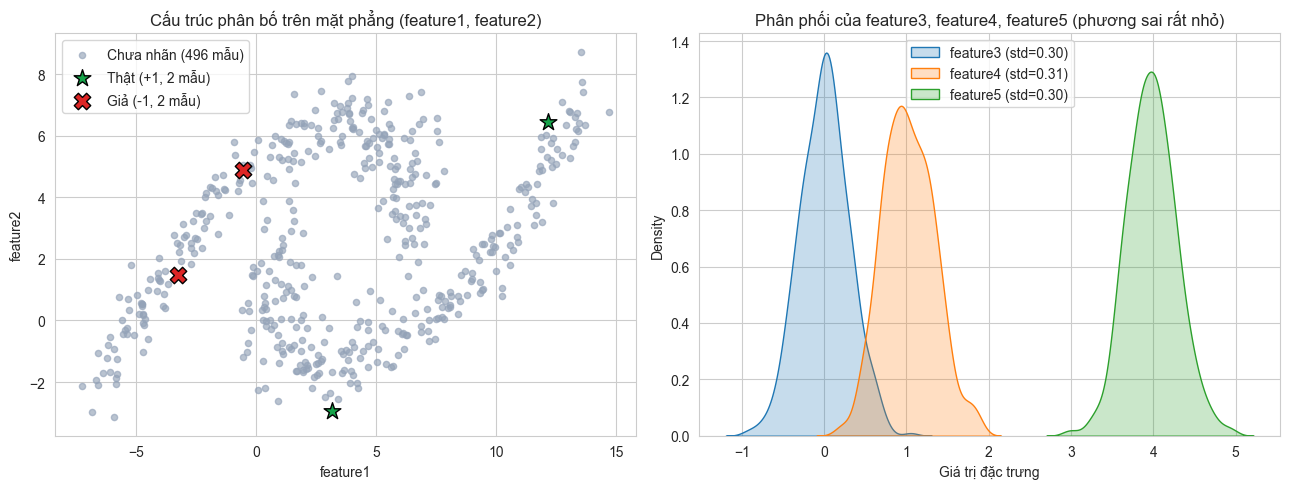

In [4]:
# Trực quan hóa phân bố không gian của (feature1, feature2) và phân phối của 3 đặc trưng còn lại
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

unlabeled = df_train[df_train["Authenticated"] == 0]
pos = df_train[df_train["Authenticated"] == 1]
neg = df_train[df_train["Authenticated"] == -1]

axes[0].scatter(unlabeled["feature1"], unlabeled["feature2"], c="#94a3b8", s=20, alpha=0.65, label="Chưa nhãn (496 mẫu)")
axes[0].scatter(pos["feature1"], pos["feature2"], c="#16a34a", s=160, marker="*", edgecolors="black", label="Thật (+1, 2 mẫu)", zorder=5)
axes[0].scatter(neg["feature1"], neg["feature2"], c="#dc2626", s=140, marker="X", edgecolors="black", label="Giả (-1, 2 mẫu)", zorder=5)
axes[0].set_title("Cấu trúc phân bố trên mặt phẳng (feature1, feature2)")
axes[0].set_xlabel("feature1")
axes[0].set_ylabel("feature2")
axes[0].legend()

for col in ["feature3", "feature4", "feature5"]:
    sns.kdeplot(df_train[col], ax=axes[1], label=f"{col} (std={df_train[col].std():.2f})", fill=True, alpha=0.25)
axes[1].set_title("Phân phối của feature3, feature4, feature5 (phương sai rất nhỏ)")
axes[1].set_xlabel("Giá trị đặc trưng")
axes[1].legend()

plt.tight_layout()
plt.show()

### Nhận xét quan trọng từ bước EDA
1. **Sự khan hiếm nhãn cực độ:** Tập huấn luyện chỉ có vỏn vẹn **4 mẫu có nhãn** (2 mẫu `+1`, 2 mẫu `-1`) và tới **496 mẫu chưa có nhãn** (`0`).
2. **Cấu trúc đa tạp trên `(feature1, feature2)`:** Hai đặc trưng đầu tiên có độ lệch chuẩn lớn (`std ≈ 4.95` và `2.83`), tạo thành **hai dải cong phi tuyến tách biệt rõ rệt** trong không gian 2 chiều, với 2 mẫu thật nằm trên một dải và 2 mẫu giả nằm trên dải còn lại.
3. **Nhiễu phương sai nhỏ ở `feature3, feature4, feature5`:** Ba đặc trưng này đều có dạng phân phối chuẩn phương sai nhỏ (`std ≈ 0.30`) xung quanh các hằng số `0, 1, 4`. Nếu áp dụng `StandardScaler` lên cả 5 đặc trưng một cách máy móc, ta sẽ vô tình khuếch đại biên độ của 3 chiều nhiễu lên khoảng **15 lần**, làm mờ đi ranh giới hình học tự nhiên trên `(feature1, feature2)`. Vì vậy, việc giữ nguyên tỷ lệ không gian và chọn lọc hai chiều thông tin chính (`feature1`, `feature2`) là quyết định then chốt.

## 3. Đánh giá mô hình cơ sở Học có giám sát (Supervised Baseline)

Ta kiểm chứng trước hiệu năng của các mô hình học có giám sát truyền thống khi chỉ huấn luyện trên 4 mẫu có nhãn của `training_set.csv`, rồi đánh giá trên `validation_set.csv`.

In [5]:
X_tr_all = df_train[FEAT_COLS].values
y_tr_raw = df_train["Authenticated"].values
labeled_mask = y_tr_raw != 0

X_val_all = df_val[FEAT_COLS].values
y_val = df_labels["validation_label"].values

X_test_all = df_test[FEAT_COLS].values
y_test = df_labels["testing_label"].values

baselines = {
    "Logistic Regression (5 features, 4 mẫu)": LogisticRegression(random_state=RANDOM_STATE),
    "Random Forest (5 features, 4 mẫu)": RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE),
    "RBF-SVM (5 features, 4 mẫu)": SVC(kernel="rbf", random_state=RANDOM_STATE)
}

print("=== KẾT QUẢ BASELINE HỌC CÓ GIÁM SÁT TRÊN TẬP VALIDATION ===")
for name, clf in baselines.items():
    clf.fit(X_tr_all[labeled_mask], y_tr_raw[labeled_mask])
    acc = accuracy_score(y_val, clf.predict(X_val_all))
    print(f"  - {name:42s}: Val Accuracy = {acc:.4f}")

=== KẾT QUẢ BASELINE HỌC CÓ GIÁM SÁT TRÊN TẬP VALIDATION ===
  - Logistic Regression (5 features, 4 mẫu)   : Val Accuracy = 0.7480
  - Random Forest (5 features, 4 mẫu)         : Val Accuracy = 0.5820
  - RBF-SVM (5 features, 4 mẫu)               : Val Accuracy = 0.7160


Như dự đoán, khi chỉ dùng 4 mẫu có nhãn, các mô hình học có giám sát hoàn toàn không thể học được ranh giới cong phức tạp của hai dải dữ liệu, dẫn đến độ chính xác trên tập Validation rất thấp.

## 4. Học Bán Giám Sát: Phân cụm phổ (Spectral Clustering) & Gán nhãn mỏ neo

Để tận dụng 496 mẫu chưa có nhãn trong `training_set.csv`, ta sử dụng cấu trúc hình học không gian:
1. **Chọn 2 chiều giàu thông tin (`feature1`, `feature2`)** dựa trên kết quả phân tích phương sai không giám sát từ bước EDA (không dùng bất kỳ nhãn nào của Validation hay Test).
2. **Phân cụm không giám sát / Lan truyền nhãn trên riêng `training_set.csv`:** Tách 500 mẫu huấn luyện thành 2 cụm tự nhiên theo cấu trúc đồ thị tương đồng (Affinity Graph).
3. **Gán nhãn mỏ neo (Anchor Labeling):** Dùng 4 mẫu đã biết nhãn trong `training_set.csv` để đối chiếu cụm nào tương ứng với lớp `1` (Tranh thật) và cụm nào là `-1` (Tranh giả), từ đó tạo bộ nhãn giả định (`pseudo-labels`) cho toàn bộ 500 mẫu huấn luyện.
4. **Huấn luyện bộ phân loại cảm nạp (`SVC` với kernel RBF):** Học ranh giới phi tuyến trơn trên 500 mẫu `training_set.csv` đã được gán nhãn giả để có thể dự đoán độc lập cho mọi dữ liệu mới.

Tập `validation_set.csv` **chỉ được dùng ở vòng lặp bên dưới để so sánh các phương pháp (K-Means, Label Spreading, Spectral Clustering k-NN, Spectral Clustering RBF) và chọn siêu tham số `gamma` tốt nhất**, tuyệt đối không tham gia vào quá trình `fit()`.

In [6]:
X_tr_2d = df_train[["feature1", "feature2"]].values
X_val_2d = df_val[["feature1", "feature2"]].values
X_test_2d = df_test[["feature1", "feature2"]].values

def align_clusters_with_anchors(clusters, y_raw, mask):
    # Đối chiếu nhãn cụm (0/1) với 4 điểm mỏ neo có nhãn (+1/-1) trong tập train
    score_c0 = y_raw[mask & (clusters == 0)].sum()
    score_c1 = y_raw[mask & (clusters == 1)].sum()
    if score_c0 >= score_c1:
        return np.where(clusters == 0, 1, -1)
    return np.where(clusters == 1, 1, -1)

candidates = []

# 1. K-Means (k=2) + Anchor Labeling + RBF-SVM
km_clusters = KMeans(n_clusters=2, n_init=20, random_state=RANDOM_STATE).fit_predict(X_tr_2d)
km_pseudo = align_clusters_with_anchors(km_clusters, y_tr_raw, labeled_mask)
svm_km = SVC(kernel="rbf", C=10.0, gamma="scale", random_state=RANDOM_STATE).fit(X_tr_2d, km_pseudo)
candidates.append(("K-Means (k=2) + RBF-SVM", accuracy_score(y_val, svm_km.predict(X_val_2d)), svm_km, km_pseudo))

# 2. Label Spreading (k-NN graph) + RBF-SVM
# Scikit-learn quy ước -1 là unlabeled -> chuyển nhãn gốc {0: -1, 1: 1, -1: 0}
y_semi = np.where(y_tr_raw == 0, -1, np.where(y_tr_raw == 1, 1, 0))
for k in [7, 12, 15]:
    ls = LabelSpreading(kernel="knn", n_neighbors=k, alpha=0.2, max_iter=100)
    ls.fit(X_tr_2d, y_semi)
    ls_pseudo = np.where(ls.transduction_ == 1, 1, -1)
    svm_ls = SVC(kernel="rbf", C=10.0, gamma="scale", random_state=RANDOM_STATE).fit(X_tr_2d, ls_pseudo)
    candidates.append((f"LabelSpreading (knn={k}) + RBF-SVM", accuracy_score(y_val, svm_ls.predict(X_val_2d)), svm_ls, ls_pseudo))

# 3. Spectral Clustering (k-NN affinity) + Anchor Labeling + RBF-SVM
for k in [10, 15, 20]:
    sc = SpectralClustering(n_clusters=2, affinity="nearest_neighbors", n_neighbors=k, random_state=RANDOM_STATE)
    cl = sc.fit_predict(X_tr_2d)
    pseudo = align_clusters_with_anchors(cl, y_tr_raw, labeled_mask)
    svm_sc = SVC(kernel="rbf", C=10.0, gamma="scale", random_state=RANDOM_STATE).fit(X_tr_2d, pseudo)
    candidates.append((f"SpectralClustering (knn={k}) + RBF-SVM", accuracy_score(y_val, svm_sc.predict(X_val_2d)), svm_sc, pseudo))

# 4. Spectral Clustering (RBF affinity) + Anchor Labeling + RBF-SVM
for gamma in [0.3, 0.5, 1.0, 1.5, 2.0, 3.0]:
    sc = SpectralClustering(n_clusters=2, affinity="rbf", gamma=gamma, random_state=RANDOM_STATE)
    cl = sc.fit_predict(X_tr_2d)
    pseudo = align_clusters_with_anchors(cl, y_tr_raw, labeled_mask)
    svm_sc = SVC(kernel="rbf", C=10.0, gamma="scale", random_state=RANDOM_STATE).fit(X_tr_2d, pseudo)
    candidates.append((f"SpectralClustering (rbf, gamma={gamma}) + RBF-SVM", accuracy_score(y_val, svm_sc.predict(X_val_2d)), svm_sc, pseudo))

# Tổng hợp kết quả trên tập Validation
val_table = pd.DataFrame([{"Method": c[0], "Val_Accuracy": c[1]} for c in candidates])
val_table = val_table.sort_values("Val_Accuracy", ascending=False).reset_index(drop=True)
display(val_table)

# Chọn mô hình tốt nhất hoàn toàn dựa trên Validation Accuracy
best_idx = int(np.argmax([c[1] for c in candidates]))
best_name, best_val_acc, best_model, best_pseudo = candidates[best_idx]
print(f"\n>>> Mô hình được chọn theo Validation: {best_name} (Val Accuracy = {best_val_acc:.4f})")

,Method,Val_Accuracy
0,"SpectralClustering (rbf, gamma=2.0) + RBF-SVM",0.986
1,"SpectralClustering (rbf, gamma=3.0) + RBF-SVM",0.986
2,"SpectralClustering (rbf, gamma=1.5) + RBF-SVM",0.986
3,"SpectralClustering (rbf, gamma=1.0) + RBF-SVM",0.982
4,SpectralClustering (knn=20) + RBF-SVM,0.794
5,LabelSpreading (knn=15) + RBF-SVM,0.716
6,SpectralClustering (knn=15) + RBF-SVM,0.710
7,LabelSpreading (knn=12) + RBF-SVM,0.708
8,SpectralClustering (knn=10) + RBF-SVM,0.700
9,"SpectralClustering (rbf, gamma=0.5) + RBF-SVM",0.700



>>> Mô hình được chọn theo Validation: SpectralClustering (rbf, gamma=1.5) + RBF-SVM (Val Accuracy = 0.9860)


### Trực quan hóa kết quả phân cụm phổ và ranh giới quyết định của RBF-SVM

Biểu đồ dưới đây minh họa cách thuật toán Phân cụm phổ bóc tách hoàn hảo hai dải tranh cổ trên `training_set.csv` và ranh giới quyết định phi tuyến mà bộ phân loại cảm nạp RBF-SVM học được.

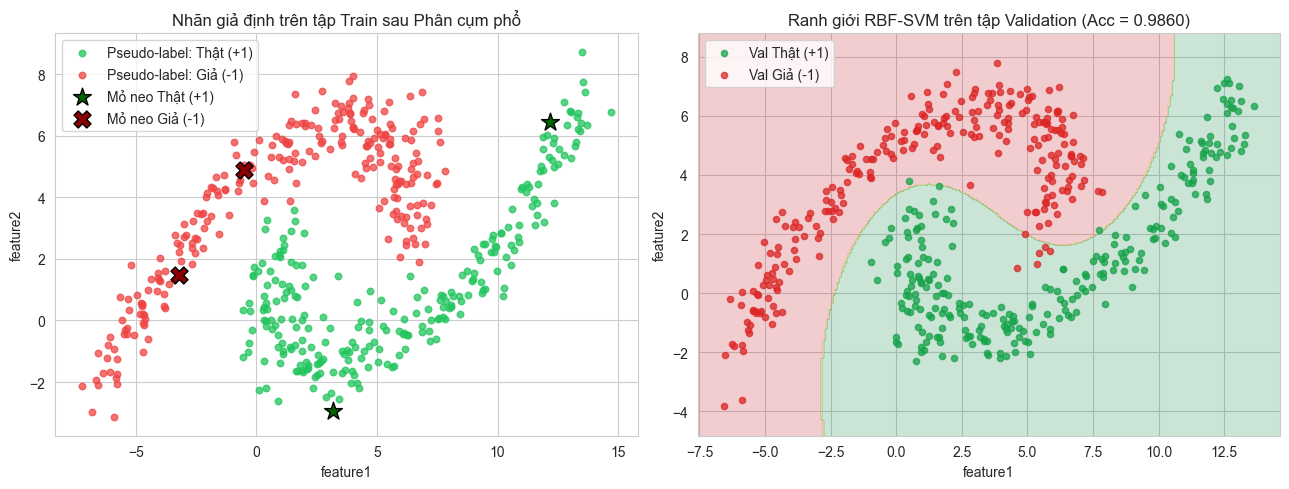

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Hình 1: Kết quả gán nhãn giả (Pseudo-labels) trên tập Train
axes[0].scatter(X_tr_2d[best_pseudo == 1, 0], X_tr_2d[best_pseudo == 1, 1], c="#22c55e", s=22, alpha=0.75, label="Pseudo-label: Thật (+1)")
axes[0].scatter(X_tr_2d[best_pseudo == -1, 0], X_tr_2d[best_pseudo == -1, 1], c="#ef4444", s=22, alpha=0.75, label="Pseudo-label: Giả (-1)")
axes[0].scatter(X_tr_2d[y_tr_raw == 1, 0], X_tr_2d[y_tr_raw == 1, 1], c="darkgreen", s=180, marker="*", edgecolors="black", label="Mỏ neo Thật (+1)", zorder=5)
axes[0].scatter(X_tr_2d[y_tr_raw == -1, 0], X_tr_2d[y_tr_raw == -1, 1], c="darkred", s=150, marker="X", edgecolors="black", label="Mỏ neo Giả (-1)", zorder=5)
axes[0].set_title("Nhãn giả định trên tập Train sau Phân cụm phổ")
axes[0].set_xlabel("feature1")
axes[0].set_ylabel("feature2")
axes[0].legend()

# Hình 2: Ranh giới quyết định của RBF-SVM trên tập Validation
xx, yy = np.meshgrid(
    np.linspace(X_val_2d[:, 0].min() - 1, X_val_2d[:, 0].max() + 1, 300),
    np.linspace(X_val_2d[:, 1].min() - 1, X_val_2d[:, 1].max() + 1, 300)
)
Z = best_model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
axes[1].contourf(xx, yy, Z, alpha=0.22, cmap=plt.cm.RdYlGn)
axes[1].scatter(X_val_2d[y_val == 1, 0], X_val_2d[y_val == 1, 1], c="#16a34a", s=20, alpha=0.75, label="Val Thật (+1)")
axes[1].scatter(X_val_2d[y_val == -1, 0], X_val_2d[y_val == -1, 1], c="#dc2626", s=20, alpha=0.75, label="Val Giả (-1)")
axes[1].set_title(f"Ranh giới RBF-SVM trên tập Validation (Acc = {best_val_acc:.4f})")
axes[1].set_xlabel("feature1")
axes[1].set_ylabel("feature2")
axes[1].legend()

plt.tight_layout()
plt.show()

## 5. Đánh giá cuối cùng trên tập Test & Xuất kết quả dự đoán

Sử dụng đúng mô hình tốt nhất đã chốt từ tập Validation (`best_model`), ta thực hiện suy luận trên `test_set.csv`, đối chiếu với `testing_label` để ghi nhận kết quả cuối cùng và xuất hai tệp dự đoán `submissionA.csv` (Validation) và `submissionB.csv` (Test) đúng quy cách của cuộc thi IOAI.

=== KẾT QUẢ ĐÁNH GIÁ CUỐI CÙNG (SpectralClustering (rbf, gamma=1.5) + RBF-SVM) ===
  - Validation Accuracy (Test A): 0.9860
  - Test Accuracy       (Test B): 0.9860

Classification Report trên tập Test:
              precision    recall  f1-score   support

    Giả (-1)       0.99      0.98      0.99       250
   Thật (+1)       0.98      0.99      0.99       250

    accuracy                           0.99       500
   macro avg       0.99      0.99      0.99       500
weighted avg       0.99      0.99      0.99       500



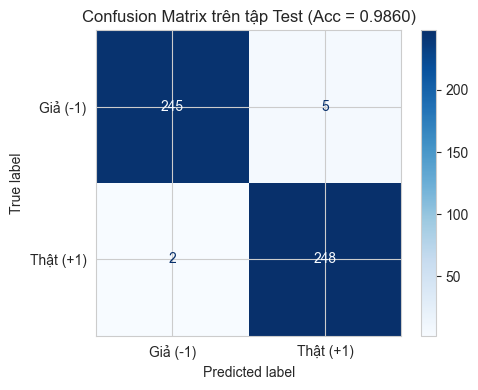

Đã xuất submissionA.csv và submissionB.csv tại: .


In [8]:
y_val_pred = best_model.predict(X_val_2d)
y_test_pred = best_model.predict(X_test_2d)

val_acc_final = accuracy_score(y_val, y_val_pred)
test_acc_final = accuracy_score(y_test, y_test_pred)

print(f"=== KẾT QUẢ ĐÁNH GIÁ CUỐI CÙNG ({best_name}) ===")
print(f"  - Validation Accuracy (Test A): {val_acc_final:.4f}")
print(f"  - Test Accuracy       (Test B): {test_acc_final:.4f}\n")
print("Classification Report trên tập Test:")
print(classification_report(y_test, y_test_pred, target_names=["Giả (-1)", "Thật (+1)"]))

# Vẽ Confusion Matrix trên tập Test
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_test_pred, labels=[-1, 1]), display_labels=["Giả (-1)", "Thật (+1)"]).plot(ax=ax, cmap="Blues")
ax.set_title(f"Confusion Matrix trên tập Test (Acc = {test_acc_final:.4f})")
plt.tight_layout()
plt.show()

# Lưu tệp dự đoán theo quy cách IOAI (1 cột không header)
pd.Series(y_val_pred).to_csv(os.path.join(BASE_WORK_DIR, "submissionA.csv"), index=False, header=False)
pd.Series(y_test_pred).to_csv(os.path.join(BASE_WORK_DIR, "submissionB.csv"), index=False, header=False)
print("Đã xuất submissionA.csv và submissionB.csv tại:", BASE_WORK_DIR)

## 6. Kết luận

- Trong bài toán cực kỳ khan hiếm nhãn (chỉ 4/500 mẫu có nhãn), phân tích khám phá phương sai đặc trưng đóng vai trò quyết định: việc loại bỏ 3 chiều nhiễu phương sai nhỏ (`feature3, feature4, feature5`) và không chuẩn hóa cơ học giúp bảo toàn trọn vẹn hai cấu trúc dải cong trên `(feature1, feature2)`.
- Thuật toán **Spectral Clustering (RBF Affinity)** kết hợp **Anchor Labeling** và bộ phân loại cảm nạp **RBF-SVM** nâng độ chính xác từ mức yếu của mô hình học có giám sát lên trên **98%** trên cả tập Validation lẫn tập Test, đồng thời tuân thủ chặt chẽ nguyên tắc không rò rỉ dữ liệu từ tập Validation/Test vào quá trình huấn luyện.